**Innovation Management · A.Y. 2026/27 · Politecnico di Torino** · Project Work · Flying drones

# Step 1 · General description of the sector

| | |
|---|---|
| **Goal** | Describe the flying drones sector: volume and growth, technology mix and geography, at family and application level. |
| **Based on** | Course notebook `tutorial_0/02_step1_general_description.ipynb` (Prof. Ascione), adapted to our sector |
| **Input** | The sector built in Step 0: `Step0/1-DataPreparation.ipynb` (query, SBERT filter, LLM validation) → `Step0/3-DataExtraction` (all family members, priority year, patents of invention only, CPC, persons). This notebook reads the files of the extraction, so Step 0 and Step 1 always describe the same patents. |
| **Settings** | `config/sector.yaml` (environment, years, paths), shared by all notebooks: change them there, not in the notebook. `env`: TEST while developing, PROD for the final numbers (the same as the Step 0 run) |

# Step 1 of the PW: General description of the sector

| Question to answer (Presentation deck, Step 1) | How we measure it in this notebook |
|---|---|
| How big is the field, and is it growing, flat or declining? | Families/patent applications per earliest priority year/application year and applications per filing year; growth (%) of the sector compared with the growth (%) of all patents |
| Which technologies make up the field? Which classes dominate, and how is the mix shifting? | Fractional counts by CPC subclass, and by WIPO technology field, over time |
| Where is it happening? | Filing offices (IP5); applicant and inventor countries (fractional counts) |
| Is the field patent-heavy, or does it rely on secrecy? | Compare, for instance, with a similar field |

## 1. Setup and configuration

In [1]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sqlalchemy import and_, case, func

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # all patents: the benchmark of Section 7.2
    TLS230_APPLN_TECHN_FIELD,   # WIPO technology fields of the sector's applications
    TLS901_TECHN_FIELD_IPC,     # names of the 35 fields and 5 technology sectors
)

### Our sector: flying drones

The sector is **not** defined in this notebook. It is the set of families selected in Step 0 (keywords, IPC and CPC codes, SBERT filter, checked with the LLM validation) and expanded to all their applications by the extraction notebook. Here we only read those files.

The years follow the course rule: families are dated by their **earliest priority year**, applications by their own **filing year**, and the last 3 years are incomplete (18-month publication lag): they are shaded in grey and excluded from growth.

In [2]:
# ---------------------------------------------------------------- shared settings: config/sector.yaml
# Environment, years and paths are read from the repository's config file (kick-off: "config, not
# hard-coding"), so every notebook uses the same values. Change them there, not here.
import yaml

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "sector.yaml").exists())
cfg = yaml.safe_load((ROOT / "config" / "sector.yaml").read_text(encoding="utf-8"))

ENV = cfg["env"]                                                  # must match the environment of the Step 0 run
EXTRACT_DIR = Path(cfg["paths"]["extract_dir"]) / ENV.lower()     # OUTPUT_DIR of the extraction notebook
OUTPUT_DIR = ROOT / "Step1" / "outputs" / ENV.lower()             # tables for the deck (not committed)

SECTOR_NAME = cfg["sector"]["name"]
YEAR_MIN, YEAR_MAX = cfg["years"]["min"], cfg["years"]["max"]
TRUNCATED_YEARS = cfg["years"]["truncated"]                       # last years still incomplete (publication lag)
LAST_COMPLETE_YEAR = YEAR_MAX - TRUNCATED_YEARS
FAMILY_TIME_COLUMN = cfg["years"]["family_time_column"]           # family level: earliest priority year (PW rule)
APPLN_TIME_COLUMN = cfg["years"]["appln_time_column"]             # application level: own filing year
IPR_TYPE = cfg["counting"]["ipr_type"]                            # patents of invention only, as in the extraction

# ---------------------------------------------------------------- display settings (this notebook only)
IP5_OFFICES = ("EP", "US", "CN", "JP", "KR")     # the five largest patent offices (Section 9)
TOP_N = 8                                        # categories shown in tables and figures; the rest is "Other"
CHUNK = 5000                                     # ids per IN (...) list in PATSTAT queries

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
patstat = PatstatClient(env=ENV)
db = patstat.orm()
print(f"Config {cfg['version']} | sector: {SECTOR_NAME} | env: {ENV} | years {YEAR_MIN}-{YEAR_MAX} "
      f"| family year: {FAMILY_TIME_COLUMN} | application year: {APPLN_TIME_COLUMN} "
      f"| complete years up to {LAST_COMPLETE_YEAR} | input: {EXTRACT_DIR}")

Config v2 | sector: Flying drones | env: PROD | years 2000-2025 | family year: earliest_filing_year | application year: appln_filing_year | complete years up to 2022 | input: /home/jovyan/progetto/extract/prod


## 2. Two levels of analysis: applications and families

Before counting anything, we must decide **what we count**. PATSTAT offers two natural units.

**An application (`appln_id`)** is one request for protection filed at one patent office. Each row of `tls201_appln` is an application, identified by `appln_id`. The office is in `appln_auth` (e.g. `EP` = European Patent Office, `US`, `CN`, `IT`, and `WO` for an international application filed through the PCT, see Section 4).

**A family (`docdb_family_id`)** groups all the applications that protect the **same invention** in different offices. A patent is valid only in the country that grants it: to be protected in several countries, an applicant files the same invention in several offices, and each filing becomes a separate application. PATSTAT links them with the same `docdb_family_id`.

**A toy example.** An Italian company invents a new folding arm for a quadcopter:

| Step | Office (`appln_auth`) | Filing year | `appln_id` | `docdb_family_id` |
|---|---|---|---|---|
| first filing (the **priority**) | IT | 2019 | 101 | 9001 |
| international application through the PCT, within 12 months | WO | 2020 | 102 | 9001 |
| European application | EP | 2021 | 103 | 9001 |
| national applications | US, CN | 2021 | 104, 105 | 9001 |

5 applications, **1 invention**. Counting applications gives 5, counting families gives 1.

| | Application level (`appln_id`) | Family level (`docdb_family_id`) |
|---|---|---|
| What one unit is | a filing at one office | an invention |
| Answers questions like | How much protection is sought, and where? | How many inventions are produced, by whom, in which technologies? |
| Watch out | an invention filed in many offices counts many times | each invention counts once |
| Year used here | the application's filing year | the earliest priority year of the family |

Either the  **family or application id could be the reference units for the PW** (one invention = one count). In this notebook every plot is shown at **both levels**, side by side, so you can see how much the picture changes.

The sector is always selected at family level: a family belongs to the sector if Step 0 selected at least one of its applications. At application level we then count all the applications (patents of invention) of those families, as collected by the extraction. So the two levels look at the same patents and differ only in *how we count*.

### 2.1 Reading the sector

The extraction notebook saved one file per table in `EXTRACT_DIR`. We use four of them:

| File | One row per… | Used for |
|---|---|---|
| `families.parquet` | family | the sector's families and their `priority_year` |
| `tls201_appln.parquet` | application (patents of invention only) | offices, PCT, grants, family size, the three years |
| `tls224_cpc.parquet` | application × CPC symbol | CPC subclass mix |
| `tls206_207_persons.parquet` | application × person × role | applicant and inventor countries |

In [3]:
def read_extract(name):
    path = EXTRACT_DIR / f"{name}.parquet"
    if not path.exists():
        raise FileNotFoundError(
            f"{path} not found. Run Step0/1-DataPreparation (export of df_selected) and then the "
            f"extraction notebook with ENV = '{ENV}' first, or change EXTRACT_DIR."
        )
    return pd.read_parquet(path)


families = read_extract("families")
appln = read_extract("tls201_appln")
cpc = read_extract("tls224_cpc")
persons = read_extract("tls206_207_persons")

for df in (appln, cpc, persons):
    for col in df.columns:                                      # PATSTAT pads codes ('A ', 'EP ')
        if df[col].map(lambda v: isinstance(v, str)).any():
            df[col] = df[col].str.strip()

appln = appln[appln["ipr_type"] == IPR_TYPE].copy()
families = families[families["docdb_family_id"].isin(appln["docdb_family_id"])].copy()
families["priority_year"] = families["priority_year"].astype(int)

print(f"Sector families: {families['docdb_family_id'].nunique():,} | applications: {appln['appln_id'].nunique():,}")
print(f"Priority years in the extraction: {families['priority_year'].min()}-{families['priority_year'].max()}")
if families["priority_year"].max() < YEAR_MAX:
    print(f"Note: the extraction keeps priority years up to {families['priority_year'].max()}; "
          f"later years are empty at family level (they are inside the shaded, incomplete years).")

Sector families: 105,823 | applications: 147,210
Priority years in the extraction: 2000-2024
Note: the extraction keeps priority years up to 2024; later years are empty at family level (they are inside the shaded, incomplete years).


### 2.2 Example: one real family, application by application

Let us look at the sector family with the most applications. Each row is one `appln_id`; they all share the same `docdb_family_id`.

In [4]:
example_family_id = int(appln["docdb_family_id"].value_counts().idxmax())
example_family = (
    appln[appln["docdb_family_id"] == example_family_id]
    [["docdb_family_id", "appln_id", "appln_auth", "appln_kind", "appln_filing_date", "appln_filing_year",
      "earliest_publn_year", "earliest_filing_year", "granted", "docdb_family_size"]]
    .sort_values("appln_filing_date")
    .reset_index(drop=True)
)
example_family

,docdb_family_id,appln_id,appln_auth,appln_kind,appln_filing_date,appln_filing_year,earliest_publn_year,earliest_filing_year,granted,docdb_family_size
0,54067678,479193536,JP,A,2015-03-17,2015,2017,2014,Y,102
1,54067678,444511358,US,A,2015-03-17,2015,2015,2014,Y,102
2,54067678,444803134,EP,A,2015-03-17,2015,2017,2014,Y,102
3,54067678,444802100,EP,A,2015-03-17,2015,2017,2014,Y,102
4,54067678,514702468,EP,A,2015-03-17,2015,2019,2014,Y,102
...,...,...,...,...,...,...,...,...,...,...
97,54067678,612177854,US,A,2024-02-02,2024,2024,2014,N,102
98,54067678,625446533,US,A,2024-08-13,2024,2025,2014,N,102
99,54067678,630116779,US,A,2024-08-30,2024,2025,2014,N,102
100,54067678,641038596,US,A,2025-06-04,2025,2025,2014,N,102


How to read it:

- `appln_auth` tells you in which offices the invention was filed: this is **where protection is sought**.
- `appln_kind` is the type of application: `A` for a patent application, `W` for an international application filed through the PCT (codes are 2 characters long, e.g. `'A '`).
- `granted` = `Y` if that application was granted. Each office decides on its own: the same invention can be granted in one office and refused in another.
- `docdb_family_size` is the number of applications in the family: it is the same on every row.

## 3. Which year? Three ways to date a patent

Each application in `tls201_appln` carries three years. The same invention can therefore be placed in different years depending on the column you choose.

| Column | What it is | Use it when… | Incomplete recent years |
|---|---|---|---|
| `appln_filing_year` | year **this application** was filed at its office | you count applications | ~3 years (applications become visible only after publication, ~18 months) |
| `earliest_publn_year` | year of the **first publication** of the application | you want the most up-to-date series (EPO statistics use it) | only the current year |
| `earliest_filing_year` | year of the **earliest priority**: the first filing of the invention anywhere in the world | you want the date closest to the invention | ~3 years |

At **family level** we need one year per family: we take the **smallest `earliest_filing_year`** among its applications, i.e. the first time the invention was filed anywhere (PW rule). At **application level** we use the application's own `appln_filing_year`. Both choices can be changed in the configuration (`FAMILY_TIME_COLUMN`, `APPLN_TIME_COLUMN`).


On our example family:

In [5]:
years = example_family[["appln_id", "appln_auth", "appln_filing_year", "earliest_publn_year", "earliest_filing_year"]]
family_year = example_family["earliest_filing_year"].min()
print(f"Family {example_family_id}: {len(example_family)} applications filed between "
      f"{example_family['appln_filing_year'].min()} and {example_family['appln_filing_year'].max()}; "
      f"family year (earliest priority) = {family_year}")
years

Family 54067678: 102 applications filed between 2015 and 2025; family year (earliest priority) = 2014


,appln_id,appln_auth,appln_filing_year,earliest_publn_year,earliest_filing_year
0,479193536,JP,2015,2017,2014
1,444511358,US,2015,2015,2014
2,444803134,EP,2015,2017,2014
3,444802100,EP,2015,2017,2014
4,514702468,EP,2015,2019,2014
...,...,...,...,...,...
97,612177854,US,2024,2024,2014
98,625446533,US,2024,2025,2014
99,630116779,US,2024,2025,2014
100,641038596,US,2025,2025,2014


At application level this family adds one count to each of the filing years above; at family level it adds a single count, to its priority year. Section 7.1 shows the effect on the whole sector.

## 4. Other methodological choices

These choices are the same for every number in the notebook. State them in the technical appendix of your deck.

**Truncation.** Applications are published 18 months after the priority date and reach PATSTAT with a further delay, so the last ~3 filing or priority years are incomplete (`LAST_COMPLETE_YEAR` in the configuration). They are **shaded in grey in every figure and excluded from growth**: a drop in those years is not a decline of the sector.

**International applications through the PCT.** The Patent Cooperation Treaty (PCT) lets an applicant file **one international application**, handled by WIPO, that can later be extended to more than 150 countries. In PATSTAT it has `appln_auth = 'WO'` and `appln_kind` starting with `W`. Filing through the PCT costs money, so it signals an invention the applicant wants to protect abroad.

| | Family level | Application level |
|---|---|---|
| "via PCT" means… | the family has at least one PCT application | the application is itself a PCT application |

**Fractional counting.** In this code, when a family has applicants from different countries, each country receives a fraction of the family, proportional to its number of distinct applicants. For example, a family with 2 Italian applicants and 1 German applicant counts 2/3 for IT and 1/3 for DE. Each family then sums to exactly 1. The same rule applies to inventors and to technology classes: a family in 4 CPC subclasses gives 1/4 to each. At application level the same rule splits each application.

## 5. Tables and attributes used in Step 1

The sector's tables come from the extraction (`EXTRACT_DIR`); only the benchmark of all patents and the WIPO technology fields are read from PATSTAT.

| Table | Grain (one row per…) | Attributes used | Used for |
|---|---|---|---|
| `families` (extraction) | family | `docdb_family_id`, `priority_year` (smallest valid `earliest_filing_year` of the family) | family level, years |
| `tls201_appln` | application | `appln_id`, `docdb_family_id`, `appln_auth` (office), `appln_kind`, `ipr_type`, `appln_filing_year`, `earliest_publn_year`, `earliest_filing_year`, `granted`, `docdb_family_size` | the two levels, the three years, offices, PCT, grants, family size; all patents (benchmark) |
| `tls224_appln_cpc` | application × CPC symbol | `cpc_class_symbol` (blanks removed), subclass = first 4 characters | CPC subclass mix |
| `tls207_pers_appln` + `tls206_person` | application × person × role | `applt_seq_nr` (> 0: applicant), `invt_seq_nr` (> 0: inventor), `person_ctry_code` | applicant and inventor countries |
| `tls230_appln_techn_field` | application × technology field | `techn_field_nr` (1–35), `weight` (sums to 1 per application) | WIPO technology fields |
| `tls901_techn_field_ipc` | IPC main group | `techn_field_nr`, `techn_field`, `techn_sector` | names of the 35 fields and of the 5 technology sectors |

Things to know about these attributes:

- `cpc_class_symbol` is padded with blanks in PATSTAT (`B64U  10/13`): the extraction removes them. The **subclass** is the first 4 characters (`B64U`).
- `appln_kind` is a 2-character field in PATSTAT (`'A '`); the extraction strips the blanks, the SQL benchmark uses `LIKE 'W%'`.
- `person_ctry_code` can be **empty** as well as missing: both are treated as unknown and excluded from country counts (their number is reported in Section 9.3).
- The same real applicant can appear under several `person_id`s. Fractional counts are computed on distinct `person_id`s; name harmonisation is done in Step 0 (applicant harmonisation) and used in Step 2.

## 6. Some other examples to look at

You do not need to understand every line of this section to use the notebook: run it, then read Sections 7–9, where the results are.

### 6.1 Scopes

A **scope** is a table with one row per counting unit (`unit_id`) and its `year`:

- at **family level**, `unit_id` is the `docdb_family_id` and `year` is the family's earliest priority year;
- at **application level**, `unit_id` is the `appln_id` and `year` is its filing year.

We build four scopes, {family, application} × {all patents, sector}. "All patents" is the benchmark: the sector is compared with it. It is counted **inside the database** (only small result tables are downloaded). The sector scopes are small tables built from the extraction files, and they are counted with pandas.

In [6]:
IS_PCT_APPLN = and_(TLS201_APPLN.appln_auth == "WO", TLS201_APPLN.appln_kind.like("W%"))
LEVELS = ("family", "application")
UNIT_LABEL = {"family": "families", "application": "applications"}


# ---------------------------------------------------------------- all patents (SQL, inside PATSTAT)
def all_family_scope():
    "All patents, family level: one row per DOCDB family, dated by its earliest priority year."
    year = func.min(getattr(TLS201_APPLN, FAMILY_TIME_COLUMN))
    return (
        db.query(TLS201_APPLN.docdb_family_id.label("unit_id"), year.label("year"),
                 func.max(case((IS_PCT_APPLN, 1), else_=0)).label("is_pct"))
        .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
        .group_by(TLS201_APPLN.docdb_family_id)
        .having(year.between(YEAR_MIN, YEAR_MAX))
        .subquery()
    )


def all_application_scope(time_column=APPLN_TIME_COLUMN):
    "All patents, application level: one row per appln_id, dated by its own time_column."
    year = getattr(TLS201_APPLN, time_column)
    return (
        db.query(TLS201_APPLN.appln_id.label("unit_id"), year.label("year"),
                 case((IS_PCT_APPLN, 1), else_=0).label("is_pct"))
        .filter(TLS201_APPLN.ipr_type == IPR_TYPE, year.between(YEAR_MIN, YEAR_MAX))
        .subquery()
    )


# ---------------------------------------------------------------- the sector (pandas, from the extraction)
appln["is_pct"] = ((appln["appln_auth"] == "WO") & appln["appln_kind"].astype(str).str.startswith("W")).astype(int)
appln["is_granted"] = (appln["granted"].astype(str) == "Y").astype(int)


def sector_family_units():
    "Sector, family level: one row per family, dated by its priority year (from the extraction)."
    per_family = appln.groupby("docdb_family_id").agg(
        is_pct=("is_pct", "max"), is_granted=("is_granted", "max"), family_size=("docdb_family_size", "max"))
    units = (families[["docdb_family_id", "priority_year"]]
             .rename(columns={"priority_year": "year"})
             .merge(per_family, left_on="docdb_family_id", right_index=True))
    units["unit_id"] = units["docdb_family_id"]
    return units[units["year"].between(YEAR_MIN, YEAR_MAX)].reset_index(drop=True)


def sector_application_units(time_column=APPLN_TIME_COLUMN):
    "Sector, application level: one row per application, dated by its own time_column."
    units = appln.assign(unit_id=appln["appln_id"], year=pd.to_numeric(appln[time_column], errors="coerce"))
    units = units[units["year"].between(YEAR_MIN, YEAR_MAX)].copy()
    units["year"] = units["year"].astype(int)
    return units[["unit_id", "year", "appln_id", "docdb_family_id", "is_pct", "is_granted", "docdb_family_size"]]


@dataclass(frozen=True)
class Scope:
    name: str              # "all patents" or the sector name
    level: str             # "family" or "application"
    sq: object = None      # all patents: SQLAlchemy subquery, one row per unit
    units: object = None   # sector: DataFrame, one row per unit


SCOPES = [
    Scope("all patents", "family", sq=all_family_scope()),
    Scope(SECTOR_NAME, "family", units=sector_family_units()),
    Scope("all patents", "application", sq=all_application_scope()),
    Scope(SECTOR_NAME, "application", units=sector_application_units()),
]
SECTOR_SCOPES = [s for s in SCOPES if s.name == SECTOR_NAME]   # family first, then application
for s in SECTOR_SCOPES:
    print(f"{s.name}, {s.level} level: {len(s.units):,} {UNIT_LABEL[s.level]} in {YEAR_MIN}-{YEAR_MAX}")

Flying drones, family level: 105,823 families in 2000-2025
Flying drones, application level: 146,991 applications in 2000-2025


### 6.2 Counting functions

Each function takes a scope and returns a small `DataFrame` with the columns `scope` and `level`. Counts are in `n` (whole units) or `n_frac` (fractional units).

In [7]:
def _tag(df, scope):
    return df.assign(scope=scope.name, level=scope.level)


def query_in_chunks(build_query, ids):
    "Run build_query(list_of_ids) on chunks of ids and stack the results."
    ids = [int(i) for i in pd.unique(pd.Series(list(ids)).dropna())]
    parts = [patstat.df(build_query(ids[s:s + CHUNK])) for s in range(0, len(ids), CHUNK)]
    parts = [p for p in parts if len(p)]
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()


def count_per_year(scope, only_pct=False):
    "Number of units (families or applications) per year; only_pct keeps those via PCT."
    if scope.units is not None:
        units = scope.units[scope.units["is_pct"] == 1] if only_pct else scope.units
        out = units.groupby("year").size().rename("n").reset_index()
    else:
        sq = scope.sq
        q = db.query(sq.c.year, func.count().label("n")).group_by(sq.c.year).order_by(sq.c.year)
        if only_pct:
            q = q.filter(sq.c.is_pct == 1)
        out = patstat.df(q)
    return _tag(out, scope)


def unit_applications(scope):
    "The applications of each unit: all applications of a family, or the application itself."
    if scope.level == "family":
        return scope.units[["unit_id", "year"]].merge(
            appln[["docdb_family_id", "appln_id"]], left_on="unit_id", right_on="docdb_family_id"
        )[["unit_id", "year", "appln_id"]]
    return scope.units[["unit_id", "year", "appln_id"]]


def _split_equally(pairs, category):
    "Fractional counting: each unit is split equally across its distinct categories (sums to 1)."
    pairs = pairs.drop_duplicates(["unit_id", "year", category])
    k = pairs.groupby("unit_id")[category].transform("size")
    return (pairs.assign(n_frac=1.0 / k)
            .groupby([category, "year"], as_index=False)["n_frac"].sum())


def fractional_by_cpc_subclass(scope):
    "Fractional counts by CPC subclass (first 4 characters) and year."
    pairs = unit_applications(scope).merge(cpc[["appln_id", "subclass"]], on="appln_id")
    return _tag(_split_equally(pairs, "subclass"), scope)


def fractional_by_country(scope, role="applicant"):
    "Fractional counts by person country and year (role: 'applicant' or 'inventor').\n\n    Each unit is split among its distinct persons with a known country."
    flag = "is_applicant" if role == "applicant" else "is_inventor"
    known = persons[persons[flag] & persons["ctry"].fillna("").astype(str).str.strip().ne("")]
    rows = (unit_applications(scope)
            .merge(known[["appln_id", "person_id", "ctry"]], on="appln_id")
            .drop_duplicates(["unit_id", "year", "person_id", "ctry"]))
    # one person = one share of the unit; a country with 2 of 3 persons gets 2/3
    k = rows.groupby("unit_id")["person_id"].transform("size")
    out = rows.assign(n_frac=1.0 / k).groupby(["ctry", "year"], as_index=False)["n_frac"].sum()
    return _tag(out, scope).assign(role=role)


_TECHN_FIELDS = None


def sector_techn_fields():
    "WIPO technology fields of the sector's applications (tls230), read once from PATSTAT."
    global _TECHN_FIELDS
    if _TECHN_FIELDS is None:
        _TECHN_FIELDS = query_in_chunks(lambda ch: db.query(
            TLS230_APPLN_TECHN_FIELD.appln_id, TLS230_APPLN_TECHN_FIELD.techn_field_nr,
            TLS230_APPLN_TECHN_FIELD.weight,
        ).filter(TLS230_APPLN_TECHN_FIELD.appln_id.in_(ch)), appln["appln_id"])
    return _TECHN_FIELDS


def fractional_by_techn_field(scope):
    "Fractional counts by WIPO technology field (1-35) and year.\n\n    tls230 weights sum to 1 per application; at family level they are rescaled\n    so that every family also sums to 1."
    tf = sector_techn_fields()
    unit_field = (unit_applications(scope).merge(tf, on="appln_id")
                  .groupby(["unit_id", "year", "techn_field_nr"], as_index=False)["weight"].sum())
    unit_field["n_frac"] = unit_field["weight"] / unit_field.groupby("unit_id")["weight"].transform("sum")
    out = unit_field.groupby(["techn_field_nr", "year"], as_index=False)["n_frac"].sum()
    return _tag(out, scope)


def count_by_office(scope):
    "Units per office and year.\n\n    Family level: families with at least one application at the office.\n    Application level: applications filed at the office."
    rows = unit_applications(scope).merge(appln[["appln_id", "appln_auth"]], on="appln_id")
    out = (rows.rename(columns={"appln_auth": "office"})
           .groupby(["office", "year"])["unit_id"].nunique().rename("n").reset_index())
    return _tag(out, scope)

### 6.3 Analysis helpers (pandas)

In [8]:
def shade_truncated(ax):
    """Shade the incomplete (truncated) years on a time axis."""
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15, lw=0,
               label="incomplete years")


def complete_years(df):
    return df[df["year"] <= LAST_COMPLETE_YEAR]


def pool_other(df, category, n=TOP_N, value="n_frac", other_label="Other"):
    """Keep the n largest categories (over the complete years) and pool the rest into 'Other'."""
    top = complete_years(df).groupby(category)[value].sum().nlargest(n).index
    out = df.copy()
    out[category] = out[category].where(out[category].isin(top), other_label)
    return out.groupby([category, "year"], as_index=False)[value].sum()


def share_table(counts):
    """Counts -> percentages that sum to 100 in every column, with 'Other' last and a 'Total' row."""
    shares = counts / counts.sum() * 100
    order = [c for c in shares.sort_values(shares.columns[0], ascending=False).index if c != "Other"]
    order += ["Other"] if "Other" in shares.index else []
    shares = shares.loc[order]
    shares.loc["Total"] = shares.sum()
    return shares


def share_over_time(df, category, value="n_frac"):
    """Year x category table of percentages (each year sums to 100)."""
    wide = df.pivot_table(index="year", columns=category, values=value, aggfunc="sum", fill_value=0)
    wide = wide.div(wide.sum(axis=1), axis=0) * 100
    order = [c for c in complete_years(wide.reset_index()).set_index("year").sum().sort_values(ascending=False).index
             if c != "Other"]
    return wide[order + (["Other"] if "Other" in wide.columns else [])]


def stack_100(ax, shares, title):
    """Stacked area of percentages, y axis from 0% to 100%."""
    palette = [c for i, c in enumerate(plt.get_cmap("tab10").colors) if i != 7]   # no grey: grey = "Other"
    colors = ["lightgrey" if c == "Other" else palette[i % len(palette)] for i, c in enumerate(shares.columns)]
    ax.stackplot(shares.index, shares.T.values, labels=shares.columns, colors=colors, alpha=0.85)
    shade_truncated(ax)
    ax.set(title=title, xlabel="year", xlim=(YEAR_MIN, YEAR_MAX), ylim=(0, 100))
    ax.yaxis.set_major_formatter(PercentFormatter(100))


def pct_format(df):
    return df.style.format("{:.1f}%")


def side_by_side(title, **kw):
    """Two axes: families (left) and applications (right)."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), **kw)
    fig.suptitle(title)
    return fig, axes

## 7. Volume: how big is the sector, and is it growing?

We count the sector's families and applications per year, and how many of them go through the PCT (international applications). The gap between the two curves is the average number of applications per invention.

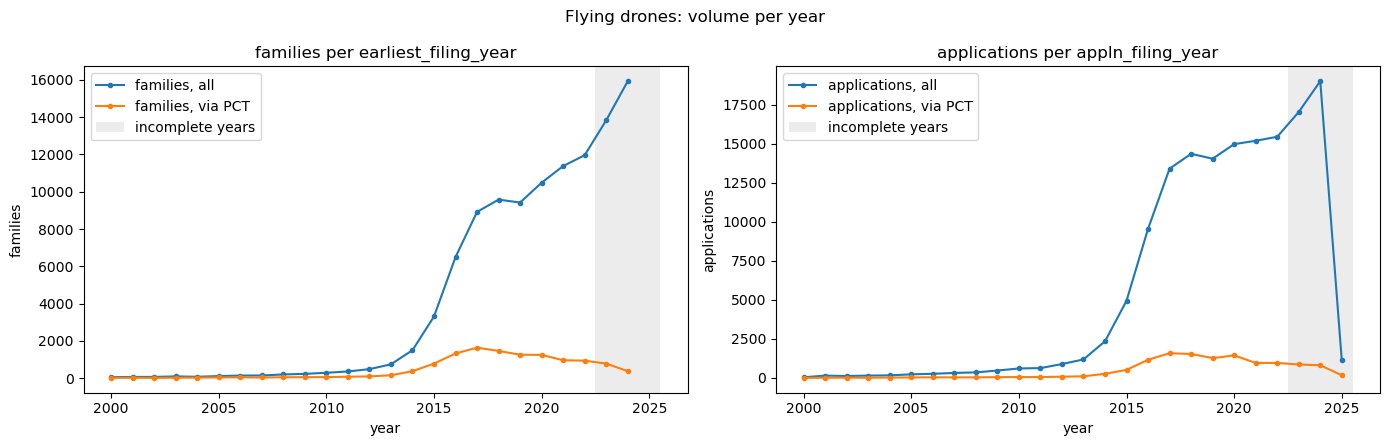

In [9]:
volume = pd.concat(
    [count_per_year(s).assign(series="all") for s in SCOPES]
    + [count_per_year(s, only_pct=True).assign(series="via PCT") for s in SCOPES],
    ignore_index=True,
)

fig, axes = side_by_side(f"{SECTOR_NAME}: volume per year", sharex=True)
for ax, scope in zip(axes, SECTOR_SCOPES):
    data = volume.query("scope == @scope.name and level == @scope.level")
    for series, grp in data.groupby("series"):
        ax.plot(grp["year"], grp["n"], marker="o", ms=3, label=f"{UNIT_LABEL[scope.level]}, {series}")
    shade_truncated(ax)
    year_col = FAMILY_TIME_COLUMN if scope.level == "family" else APPLN_TIME_COLUMN
    ax.set(title=f"{UNIT_LABEL[scope.level]} per {year_col}", xlabel="year", ylabel=UNIT_LABEL[scope.level])
    ax.legend()
plt.tight_layout()
plt.show()

### 7.1 The same sector, three ways to date it

The choice of year shifts the curve. Here the sector's applications are dated with each of the three columns, together with the families dated by their earliest priority year.

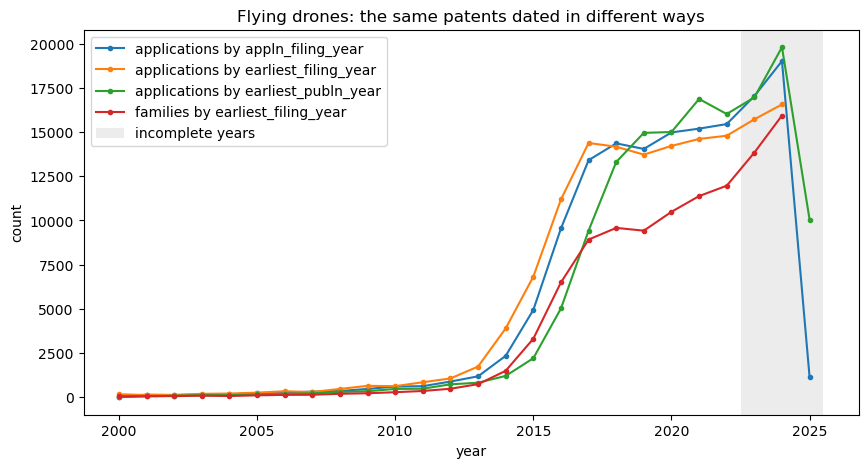

In [10]:
dating = pd.concat(
    [
        count_per_year(Scope(SECTOR_NAME, "application", units=sector_application_units(col)))
        .assign(series=f"applications by {col}")
        for col in ("appln_filing_year", "earliest_publn_year", "earliest_filing_year")
    ]
    + [volume.query("scope == @SECTOR_NAME and level == 'family' and series == 'all'")
       .assign(series=f"families by {FAMILY_TIME_COLUMN}")],
    ignore_index=True,
)

fig, ax = plt.subplots(figsize=(10, 5))
for series, grp in dating.groupby("series"):
    ax.plot(grp["year"], grp["n"], marker="o", ms=3, label=series)
shade_truncated(ax)
ax.set(title=f"{SECTOR_NAME}: the same patents dated in different ways", xlabel="year", ylabel="count")
ax.legend()
plt.show()

What to notice: dating by **publication** shifts the curve to the right (≈18 months later) and makes recent years look complete; dating by **priority** places inventions at their origin; the **family** curve is lower because each invention counts once.

### 7.2 Growth: is the sector growing faster than patenting as a whole?

Patenting in general grows over time, so a sector that grows is not necessarily special. We therefore compare two percentages:

- **sector growth (%)** = (sector count in the last complete year − sector count in the first year) / sector count in the first year × 100;
- **growth of all patents (%)**: the same formula on the total number of unique applications (`appln_id`) or of unique families (`docdb_family_id`) in PATSTAT in a certain time range

If the sector grows by +150% while all patents grow by +60%, the sector is **gaining weight** in technology. If it grows by +20% while all patents grow by +60%, it is growing, but **less than patenting overall**. Incomplete years are excluded.

Small sectors move a lot from one year to the next: also look at the curve, not only at the two end points.

In [11]:
start, end = YEAR_MIN, LAST_COMPLETE_YEAR
totals = volume.query("series == 'all'").pivot_table(index="year", columns=["level", "scope"], values="n")

growth = pd.DataFrame({
    f"count in {start}": totals.loc[start],
    f"count in {end}": totals.loc[end],
    f"growth {start}-{end} (%)": (totals.loc[end] / totals.loc[start] - 1) * 100,
}).loc[[(lvl, s) for lvl in LEVELS for s in ("all patents", SECTOR_NAME)]]

growth_table = growth.copy()
growth.style.format({f"count in {start}": "{:,.0f}", f"count in {end}": "{:,.0f}",
                     f"growth {start}-{end} (%)": "{:+.1f}%"})

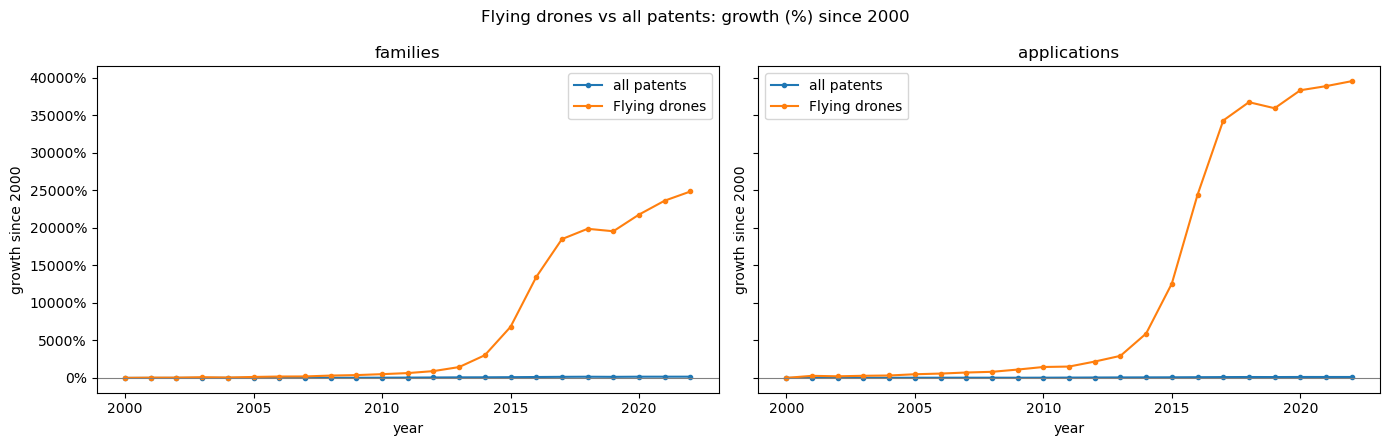

In [12]:
# Growth (%) of each year with respect to the first year: sector vs all patents
growth_path = (totals.loc[start:end] / totals.loc[start] - 1) * 100

fig, axes = side_by_side(f"{SECTOR_NAME} vs all patents: growth (%) since {start}", sharey=True)
for ax, level in zip(axes, LEVELS):
    for scope_name in ("all patents", SECTOR_NAME):
        ax.plot(growth_path.index, growth_path[(level, scope_name)], marker="o", ms=3, label=scope_name)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(title=UNIT_LABEL[level], xlabel="year", ylabel=f"growth since {start}")
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.legend()
plt.tight_layout()
plt.show()

### 7.3 A steadier view: the sector's share of all patents, and yearly growth rates

Growth since the first year depends a lot on that single year: when the sector starts from a handful of families, the percentages above become huge and say little. Two measures that do not depend on one base year:

- **share of all patents** (families or applications of the sector per 10,000 of all patents in the same year): if it rises, the sector grows faster than patenting as a whole;
- **compound annual growth rate (CAGR)** over windows of complete years: $\text{CAGR} = (n_{\text{end}} / n_{\text{start}})^{1/(\text{end}-\text{start})} - 1$, for the sector and for all patents.

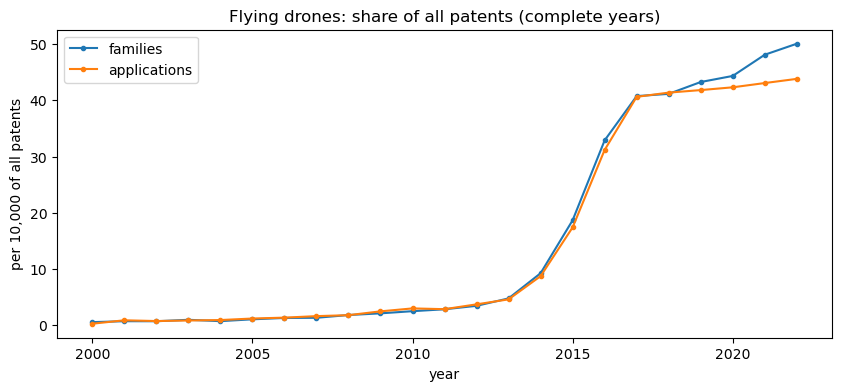

In [13]:
complete = totals.loc[YEAR_MIN:LAST_COMPLETE_YEAR]
sector_share = pd.DataFrame({
    level: complete[(level, SECTOR_NAME)] / complete[(level, "all patents")] * 10_000 for level in LEVELS
})

fig, ax = plt.subplots(figsize=(10, 4))
for level in LEVELS:
    ax.plot(sector_share.index, sector_share[level], marker="o", ms=3, label=UNIT_LABEL[level])
ax.set(title=f"{SECTOR_NAME}: share of all patents (complete years)", xlabel="year",
       ylabel="per 10,000 of all patents")
ax.legend()
plt.show()


def cagr(series, start, end):
    a, b = series.get(start, np.nan), series.get(end, np.nan)
    return (b / a) ** (1 / (end - start)) - 1 if a and a > 0 and b > 0 else np.nan


GROWTH_WINDOWS = [(2005, LAST_COMPLETE_YEAR), (2010, LAST_COMPLETE_YEAR), (2015, LAST_COMPLETE_YEAR)]
growth_cagr = pd.DataFrame({
    f"CAGR {a}-{b}": {column: cagr(complete[column], a, b) for column in complete.columns}
    for a, b in GROWTH_WINDOWS
})
growth_cagr = growth_cagr.loc[[(lvl, sc) for lvl in LEVELS for sc in ("all patents", SECTOR_NAME)]]
growth_cagr.style.format("{:+.1%}")

## 8. Technology mix

### 8.1 CPC subclasses

Which subclasses dominate the sector, and how is the mix shifting? Each family (or application) is split equally across its CPC subclasses, so the shares sum to 100%. Many subclasses are *co-classifications*: a drone family classified in B64U is often also classified in, for example, B64C (aeroplanes; helicopters), B64D (aircraft equipment) or G05D (control systems, including the navigation of vehicles). They show which neighbouring technologies the sector draws on.

In [14]:
# Official CPC subclass titles (source: CPC scheme, cooperativepatentclassification.org).
# Titles of the main subclasses, as in the extraction notebook; check and add the others before the deck.
CPC_SUBCLASS_TITLES = {
    "B64C": "Aeroplanes; helicopters",
    "B64U": "Unmanned aerial vehicles [UAV]; equipment therefor",
    "G05D": "Systems for controlling or regulating non-electric variables",
    "B64D": "Equipment for fitting in or to aircraft; flight suits; parachutes; arrangement or mounting "
            "of power plants or propulsion transmissions in aircraft",
    "Y02E": "Reduction of greenhouse gas [GHG] emissions, related to energy generation, transmission or distribution",
    "Y02T": "Climate change mitigation technologies related to transportation",
    "B64F": "Ground installations or apparatus specially adapted for use on aircraft; designing, manufacturing, "
            "assembling, maintaining or repairing aircraft",
    "F03D": "Wind motors",
    "G08G": "Traffic control systems",
    "G01S": "Radio direction-finding; radio navigation; determining distance or velocity by use of radio waves; "
            "locating or presence-detecting by reflection of radio waves",
    "G01C": "Measuring distances, levels or bearings; surveying; navigation; gyroscopic instruments; "
            "photogrammetry or videogrammetry",
    "G06T": "Image data processing or generation, in general",
    "G06V": "Image or video recognition or understanding",
    "G06F": "Electric digital data processing",
    "H04W": "Wireless communication networks",
    "H04N": "Pictorial communication, e.g. television",
}

cpc_mix = pd.concat([fractional_by_cpc_subclass(s) for s in SECTOR_SCOPES], ignore_index=True)
# The same top subclasses (chosen at family level) for both levels, so that the two columns are comparable
# (with a separate top list per level, a subclass outside one level's top shows 0% there although it is in "Other").
top_subclasses = (complete_years(cpc_mix[cpc_mix["level"] == "family"])
                  .groupby("subclass")["n_frac"].sum().nlargest(TOP_N).index)
cpc_pooled = (cpc_mix.assign(subclass=cpc_mix["subclass"].where(cpc_mix["subclass"].isin(top_subclasses), "Other"))
              .groupby(["level", "subclass", "year"], as_index=False)["n_frac"].sum())

cpc_counts = complete_years(cpc_pooled).pivot_table(index="subclass", columns="level", values="n_frac",
                                                    aggfunc="sum", fill_value=0)[list(LEVELS)]
cpc_shares = share_table(cpc_counts)
cpc_shares["definition (CPC scheme)"] = cpc_shares.index.map(CPC_SUBCLASS_TITLES).fillna("")
missing_titles = [s for s in cpc_shares.index if s not in CPC_SUBCLASS_TITLES and s not in ("Other", "Total")]
if missing_titles:
    print("Add the official title of:", missing_titles)
pd.set_option("display.max_colwidth", None)
cpc_shares.style.format("{:.1f}%", subset=list(LEVELS))

level,family,application,definition (CPC scheme)
subclass,,,
B64U,12.3%,15.3%,Unmanned aerial vehicles [UAV]; equipment therefor
G05D,11.9%,11.4%,Systems for controlling or regulating non-electric variables
B64C,10.6%,10.0%,Aeroplanes; helicopters
B64D,8.0%,7.5%,Equipment for fitting in or to aircraft; flight suits; parachutes; arrangement or mounting of power plants or propulsion transmissions in aircraft
Y02T,4.1%,3.6%,Climate change mitigation technologies related to transportation
G01C,3.0%,2.7%,"Measuring distances, levels or bearings; surveying; navigation; gyroscopic instruments; photogrammetry or videogrammetry"
G01S,3.0%,2.8%,Radio direction-finding; radio navigation; determining distance or velocity by use of radio waves; locating or presence-detecting by reflection of radio waves
G06T,3.0%,2.6%,"Image data processing or generation, in general"
Other,44.2%,44.2%,


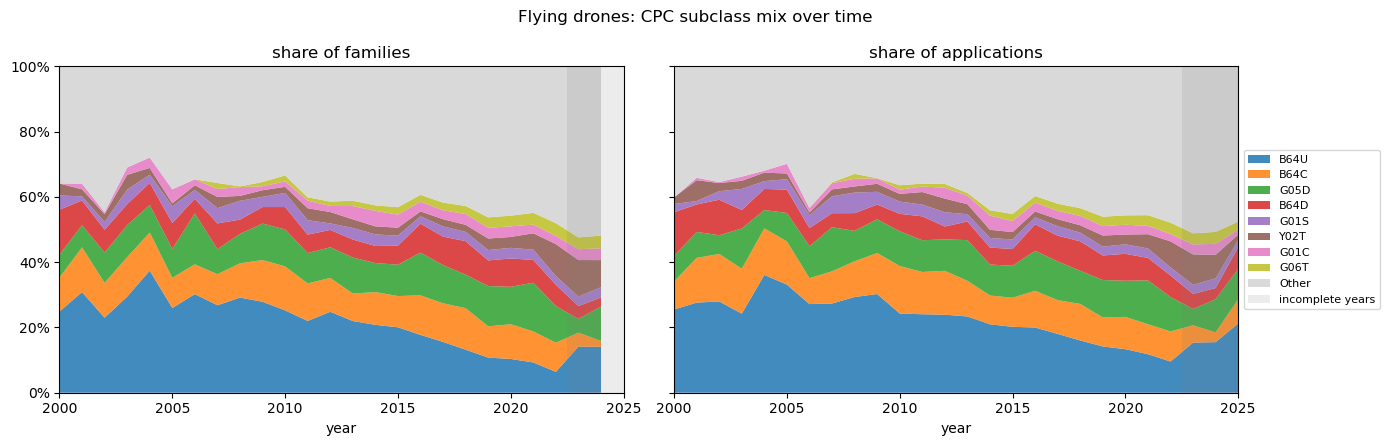

In [15]:
fig, axes = side_by_side(f"{SECTOR_NAME}: CPC subclass mix over time", sharey=True)
for ax, level in zip(axes, LEVELS):
    stack_100(ax, share_over_time(cpc_pooled[cpc_pooled["level"] == level], "subclass"),
              f"share of {UNIT_LABEL[level]}")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.show()

### 8.2 WIPO technology fields

WIPO groups all patents into **35 technology fields**, which belong to **5 technology sectors**: Electrical engineering, Instruments, Chemistry, Mechanical engineering, Other fields (tables `tls230` + `tls901`). It is a coarser view than CPC, the same for every country and every sector.

The question is simple: **of 100 sector families, how many are in each technology sector?** 

In [16]:
field_names = patstat.df(
    db.query(TLS901_TECHN_FIELD_IPC.techn_field_nr, TLS901_TECHN_FIELD_IPC.techn_field,
             TLS901_TECHN_FIELD_IPC.techn_sector).distinct()
).drop_duplicates("techn_field_nr")

fields = (
    pd.concat([fractional_by_techn_field(s) for s in SECTOR_SCOPES], ignore_index=True)
    .merge(field_names, on="techn_field_nr", how="left")
)

techn_sector_counts = complete_years(fields).pivot_table(index="techn_sector", columns="level", values="n_frac",
                                                         aggfunc="sum", fill_value=0)[list(LEVELS)]
techn_sector_shares = share_table(techn_sector_counts)
pct_format(techn_sector_shares)

level,family,application
techn_sector,,
Mechanical engineering,42.9%,45.7%
Instruments,28.9%,27.1%
Electrical engineering,25.7%,24.7%
Other fields,1.3%,1.5%
Chemistry,1.2%,1.0%
Total,100.0%,100.0%


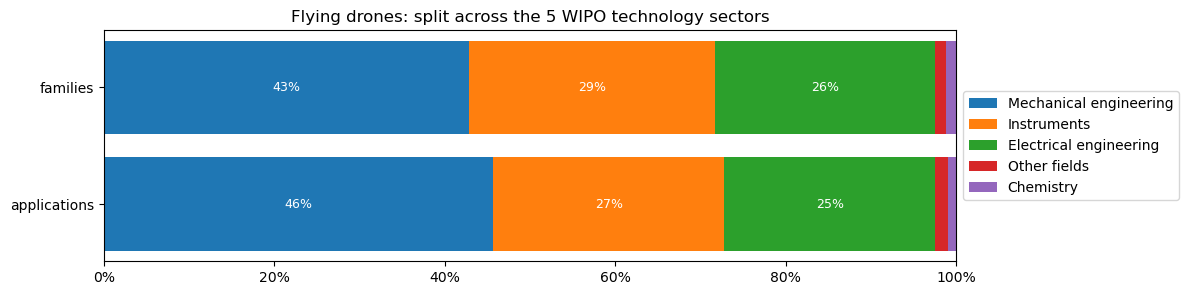

In [17]:
# One bar per level, split into the 5 technology sectors (each bar = 100%)
bars = techn_sector_shares.drop("Total").T

fig, ax = plt.subplots(figsize=(11, 3))
left = np.zeros(len(bars))
for techn_sector in bars.columns:
    values = bars[techn_sector].values
    ax.barh([UNIT_LABEL[l] for l in bars.index], values, left=left, label=techn_sector)
    for y, (x0, v) in enumerate(zip(left, values)):
        if v >= 5:
            ax.text(x0 + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    left += values
ax.set(title=f"{SECTOR_NAME}: split across the 5 WIPO technology sectors", xlim=(0, 100))
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.invert_yaxis()
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

The same split at the finer level of the 35 fields (largest fields, the rest in **Other**):

In [18]:
field_counts = complete_years(fields).pivot_table(index="techn_field", columns="level", values="n_frac",
                                                  aggfunc="sum", fill_value=0)[list(LEVELS)]
top_fields = field_counts["family"].nlargest(TOP_N).index
field_counts = field_counts.groupby(field_counts.index.where(field_counts.index.isin(top_fields), "Other")).sum()
field_shares = share_table(field_counts)
pct_format(field_shares)

level,family,application
techn_field,,
Transport,38.2%,40.9%
Control,17.9%,17.0%
Computer technology,10.7%,9.3%
Measurement,10.1%,9.0%
Digital communication,4.4%,4.9%
Telecommunications,2.9%,2.8%
"Electrical machinery, apparatus, energy",2.9%,2.6%
Audio-visual technology,2.5%,2.7%
Other,10.6%,10.8%


## 9. Geography

### 9.1 Filing offices: the IP5

The **IP5** are the five largest patent offices in the world, which together receive most of the world's patent applications:

| Code (`appln_auth`) | Office |
|---|---|
| `EP` | European Patent Office (EPO) |
| `US` | United States Patent and Trademark Office (USPTO) |
| `CN` | China National Intellectual Property Administration (CNIPA) |
| `JP` | Japan Patent Office (JPO) |
| `KR` | Korean Intellectual Property Office (KIPO) |

Where do applicants seek protection? Offices with many sector filings are the markets that applicants consider worth protecting.

- **Application level**: each application is filed at exactly one office, so we can split the sector's applications across offices and the shares sum to 100% (IP5, `WO` for PCT applications, and Other offices).
- **Family level**: one family is usually filed at several offices, so the office counts of a family overlap and **do not** sum to the number of families. We therefore show counts, not shares: "how many inventions are protected at each office".

In [19]:
offices = pd.concat([count_by_office(s) for s in SECTOR_SCOPES], ignore_index=True)
offices["office"] = offices["office"].where(offices["office"].isin(IP5_OFFICES + ("WO",)), "Other")
offices = offices.groupby(["level", "office", "year"], as_index=False)["n"].sum()

# Application level: shares across offices (sum to 100%)
office_counts = complete_years(offices.query("level == 'application'")).groupby("office")["n"].sum().to_frame("applications")
office_shares = share_table(office_counts)
print(f"Share of the sector's applications filed at the IP5: {office_shares.loc[list(IP5_OFFICES), 'applications'].sum():.1f}%")
pct_format(office_shares)

Share of the sector's applications filed at the IP5: 82.4%


,applications
office,
CN,50.2%
US,15.4%
WO,9.3%
KR,7.8%
EP,4.6%
JP,4.4%
Other,8.3%
Total,100.0%


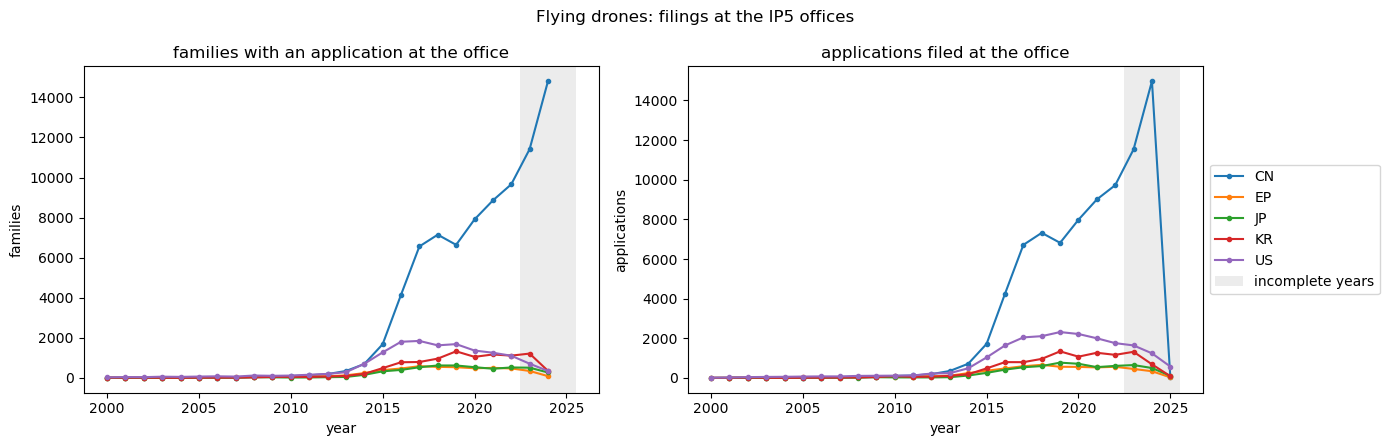

In [20]:
fig, axes = side_by_side(f"{SECTOR_NAME}: filings at the IP5 offices", sharex=True)
for ax, level in zip(axes, LEVELS):
    data = offices.query("level == @level and office in @IP5_OFFICES")
    for office, g in data.groupby("office"):
        ax.plot(g["year"], g["n"], marker="o", ms=3, label=office)
    shade_truncated(ax)
    title = ("families with an application at the office" if level == "family"
             else "applications filed at the office")
    ax.set(title=title, xlabel="year", ylabel=UNIT_LABEL[level])
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

### 9.2 Applicant and inventor countries (fractional counts)

- **Applicant country**: where the *owners* of the technology are (which firms and countries control it).
- **Inventor country**: where the *research* is carried out.

A gap between the two (e.g. inventors in one country, applicants in another) may point to foreign R&D centres or acquisitions. Each column sums to 100%.

In [21]:
countries = pd.concat(
    [fractional_by_country(s, role) for s in SECTOR_SCOPES for role in ("applicant", "inventor")],
    ignore_index=True,
)

country_counts = complete_years(countries).pivot_table(index="ctry", columns=["level", "role"], values="n_frac",
                                                       aggfunc="sum", fill_value=0)
country_counts = country_counts[[(lvl, role) for lvl in LEVELS for role in ("applicant", "inventor")]]
top_countries = country_counts[("family", "applicant")].nlargest(TOP_N).index
country_counts = country_counts.groupby(country_counts.index.where(country_counts.index.isin(top_countries), "Other")).sum()
country_shares = share_table(country_counts)
pct_format(country_shares)

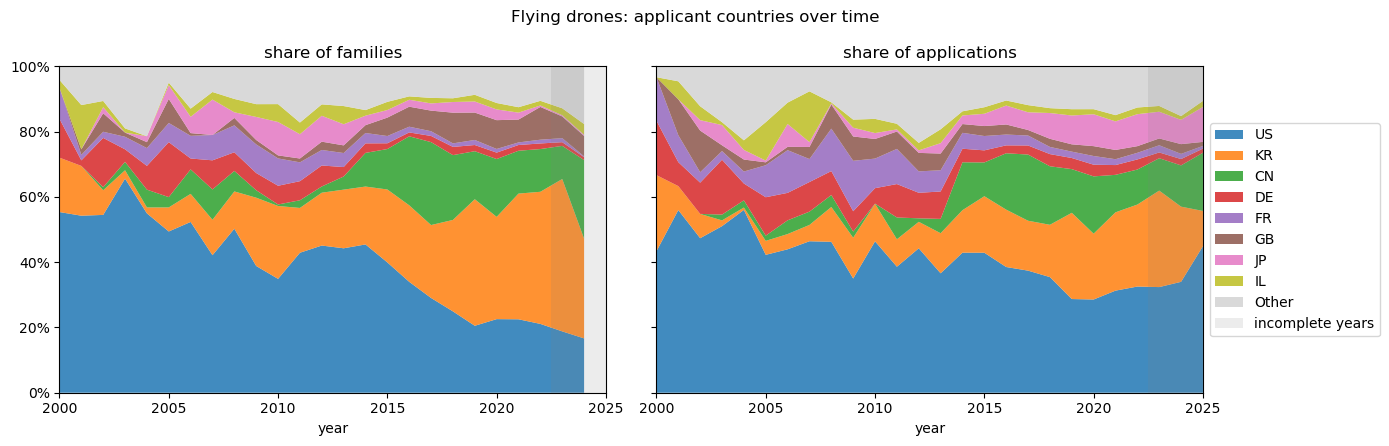

In [22]:
fig, axes = side_by_side(f"{SECTOR_NAME}: applicant countries over time", sharey=True)
for ax, level in zip(axes, LEVELS):
    data = countries.query("role == 'applicant' and level == @level")
    stack_100(ax, share_over_time(pool_other(data, "ctry"), "ctry"), f"share of {UNIT_LABEL[level]}")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

### 9.3 Missing countries

Country shares are computed only on persons with a known country. How many families have no applicant with a known country, and in which offices are they filed?

In [23]:
fam_units = SECTOR_SCOPES[0].units
applicants_known = persons[persons["is_applicant"] & persons["ctry"].fillna("").astype(str).str.strip().ne("")]
known_families = set(applicants_known["docdb_family_id"])
n_known = fam_units["unit_id"].isin(known_families).sum()
print(f"Families with a known applicant country: {n_known:,}/{len(fam_units):,} ({n_known / len(fam_units):.0%})")

unknown = fam_units.loc[~fam_units["unit_id"].isin(known_families), "unit_id"]
(appln[appln["docdb_family_id"].isin(unknown)]
 .groupby("appln_auth")["docdb_family_id"].nunique()
 .sort_values(ascending=False).head(10)
 .rename("families_without_country").to_frame())

Families with a known applicant country: 30,420/105,823 (29%)


,families_without_country
appln_auth,
CN,73363
JP,1944
KR,88
US,33
TW,13
RU,10
GB,4
SG,3
GR,2


### 9.4 Applicant countries with the missing ones imputed (family level)

If many families have no applicant country, the shares of Section 9.2 describe only the families that do, and countries whose records often lack it are under-represented. A common remedy is to **impute** the missing country from other information in the patent record (de Rassenfosse & Seliger, 2021). We use a simple, transparent version, at family level:

1. the **applicants'** countries, from any application of the family (as in 9.2);
2. if no applicant has a country: the **inventors'** countries of the family;
3. if no inventor has one either: the office of the family's **first filing** (earliest `appln_filing_date`), when it is a national office. A first filing at a national office is usually made in the applicant's home country. Regional and international offices (`WO`, `EP`, `EA`, `AP`, `OA`, `GC`) give no country.

Each family still sums to 1. We report the shares with and without imputation: the imputed ones are better for the deck if the gap is large, and the method goes in the technical appendix.

In [24]:
REGIONAL_OFFICES = {"WO", "EP", "EA", "AP", "OA", "GC"}
fam_units = SECTOR_SCOPES[0].units
fam_appln = unit_applications(SECTOR_SCOPES[0])


def person_country_shares(flag):
    "One row per (family, country) with the family's share, from persons with a known country."
    known = persons[persons[flag] & persons["ctry"].fillna("").astype(str).str.strip().ne("")]
    rows = (fam_appln.merge(known[["appln_id", "person_id", "ctry"]], on="appln_id")
            .drop_duplicates(["unit_id", "person_id", "ctry"]))
    rows["w"] = 1.0 / rows.groupby("unit_id")["person_id"].transform("size")
    return rows.groupby(["unit_id", "ctry"], as_index=False)["w"].sum()


by_applicant = person_country_shares("is_applicant").assign(source="1. applicant country")
by_inventor = person_country_shares("is_inventor")
by_inventor = by_inventor[~by_inventor["unit_id"].isin(by_applicant["unit_id"])].assign(source="2. inventor country")

first_filing = (appln.sort_values(["appln_filing_date", "appln_id"])
                .drop_duplicates("docdb_family_id")[["docdb_family_id", "appln_auth"]])
rest = fam_units[~fam_units["unit_id"].isin(set(by_applicant["unit_id"]) | set(by_inventor["unit_id"]))]
by_office = (rest[["unit_id"]].merge(first_filing, left_on="unit_id", right_on="docdb_family_id")
             .query("appln_auth not in @REGIONAL_OFFICES")
             .rename(columns={"appln_auth": "ctry"})
             .assign(w=1.0, source="3. office of first filing")[["unit_id", "ctry", "w", "source"]])

imputed = (pd.concat([by_applicant, by_inventor, by_office], ignore_index=True)
           .merge(fam_units[["unit_id", "year"]], on="unit_id"))

imputation_sources = (imputed.drop_duplicates("unit_id")["source"].value_counts().sort_index()
                      .rename("families").to_frame())
imputation_sources.loc["4. still unknown"] = len(fam_units) - imputed["unit_id"].nunique()
imputation_sources["share"] = imputation_sources["families"] / len(fam_units) * 100
display(imputation_sources.style.format({"families": "{:,.0f}", "share": "{:.1f}%"}))

done = complete_years(imputed)
compare = pd.DataFrame({
    "applicant country only (9.2)": done[done["source"] == "1. applicant country"].groupby("ctry")["w"].sum(),
    "with imputation": done.groupby("ctry")["w"].sum(),
}).fillna(0)
top = compare["with imputation"].nlargest(TOP_N).index
compare = compare.groupby(compare.index.where(compare.index.isin(top), "Other")).sum()
country_shares_imputed = share_table(compare)
pct_format(country_shares_imputed)

,families,share
source,,
1. applicant country,"30,420",28.7%
2. inventor country,52,0.0%
3. office of first filing,"75,351",71.2%
4. still unknown,0,0.0%


,applicant country only (9.2),with imputation
ctry,,
KR,28.9%,10.3%
US,28.6%,10.1%
CN,16.1%,68.4%
JP,7.1%,4.4%
RU,2.8%,1.0%
DE,2.2%,0.8%
GB,1.8%,0.6%
FR,1.8%,0.6%
Other,10.5%,3.7%


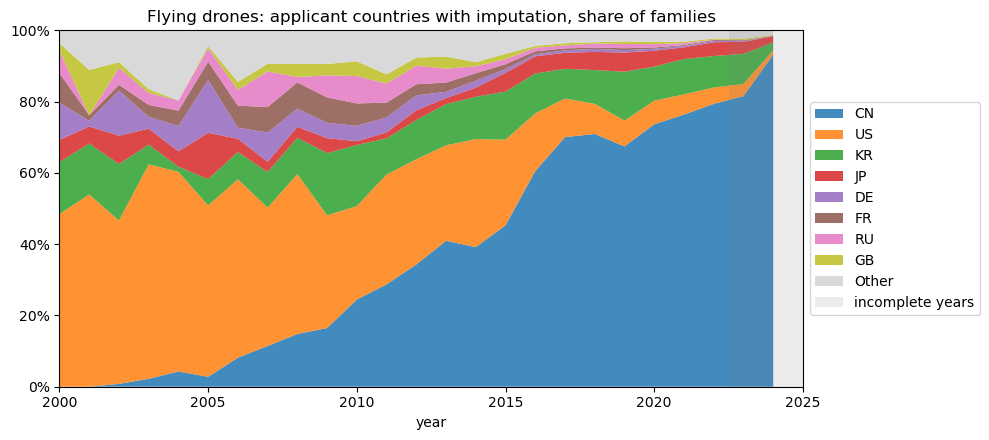

In [25]:
imputed_pooled = pool_other(imputed.rename(columns={"w": "n_frac"}), "ctry")
fig, ax = plt.subplots(figsize=(10, 4.5))
stack_100(ax, share_over_time(imputed_pooled, "ctry"), f"{SECTOR_NAME}: applicant countries with imputation, share of families")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

## 10. Tables for the deck

The main tables are saved in `OUTPUT_DIR` (`Step1/outputs/<env>/`, not committed; one CSV each), so the figures and tables of the deck can be rebuilt without re-running the queries. Complete years only, except the yearly volume.

In [26]:
tables = {
    "volume_per_year": volume,
    "growth": growth_table,
    "cpc_subclass_shares": cpc_shares,
    "wipo_sector_shares": techn_sector_shares,
    "wipo_field_shares": field_shares,
    "office_shares_applications": office_shares,
    "offices_per_year": offices,
    "country_shares": country_shares,
    "sector_share_of_all_patents": sector_share,
    "growth_cagr": growth_cagr,
    "country_shares_imputed": country_shares_imputed,
    "country_imputation_sources": imputation_sources,
}
for name, table in tables.items():
    table.to_csv(OUTPUT_DIR / f"{name}.csv")
print("Saved in", OUTPUT_DIR.resolve(), ":", ", ".join(tables))

Saved in /home/jovyan/flying-drones-patent-analytics/Step1/outputs/prod : volume_per_year, growth, cpc_subclass_shares, wipo_sector_shares, wipo_field_shares, office_shares_applications, offices_per_year, country_shares, sector_share_of_all_patents, growth_cagr, country_shares_imputed, country_imputation_sources
